# Logistic Regression with the Breast Cancer Dataset

A step-by-step introduction to classification with scikit-learn. The built-in dataset contains measurements from breast mass samples. This is a learning demo, not a medical tool.

## 1. Import the tools

We will load the dataset, split it into training and test sets, scale its features, train logistic regression, and measure how well it predicts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 2. Load the data

Each row is a sample and each column is a measured feature. The target is the class we want the model to predict: `0` means malignant and `1` means benign.

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

print(f"Samples: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Class names (target values 0, 1): {data.target_names}")
print(f"First five feature names: {data.feature_names[:5]}")

Samples: 569
Features: 30
Class names (target values 0, 1): ['malignant' 'benign']
First five feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']


## 3. Take a quick look

Here are the first five values for the first five features, followed by the number of samples in each class. The plots show class balance and how two measurements relate to the target.

In [3]:
print("First five samples (first five features):")
print(X[:5, :5])

for class_value, class_name in enumerate(data.target_names):
    print(f"{class_name}: {(y == class_value).sum()} samples")

First five samples (first five features):
[[1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01]
 [2.057e+01 1.777e+01 1.329e+02 1.326e+03 8.474e-02]
 [1.969e+01 2.125e+01 1.300e+02 1.203e+03 1.096e-01]
 [1.142e+01 2.038e+01 7.758e+01 3.861e+02 1.425e-01]
 [2.029e+01 1.434e+01 1.351e+02 1.297e+03 1.003e-01]]
malignant: 212 samples
benign: 357 samples


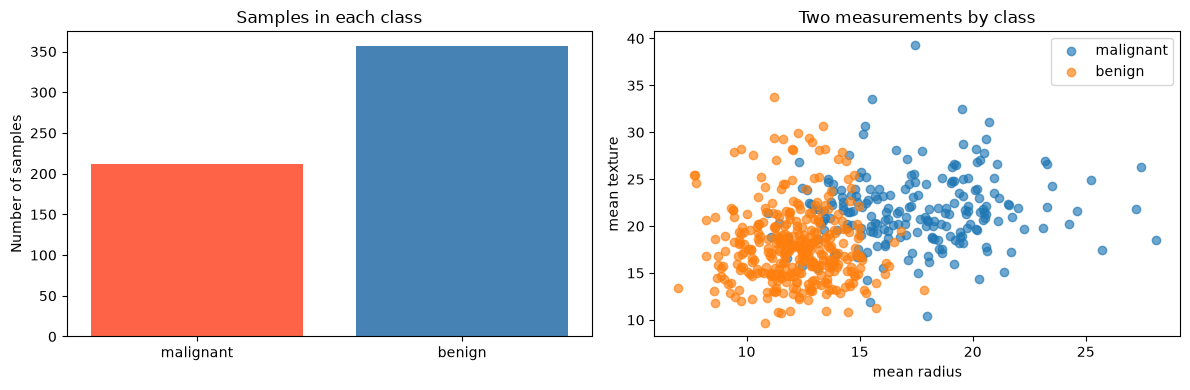

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

class_counts = [(y == class_value).sum() for class_value in range(len(data.target_names))]
axes[0].bar(data.target_names, class_counts, color=["tomato", "steelblue"])
axes[0].set_title("Samples in each class")
axes[0].set_ylabel("Number of samples")

for class_value, class_name in enumerate(data.target_names):
    samples = y == class_value
    axes[1].scatter(X[samples, 0], X[samples, 1], label=class_name, alpha=0.65)
axes[1].set_xlabel(data.feature_names[0])
axes[1].set_ylabel(data.feature_names[1])
axes[1].set_title("Two measurements by class")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Split into training and test sets

The model learns from the training set. We hold out the test set to check performance on samples it did not train on. Stratification keeps the class proportions similar in both sets; the random seed makes the split repeatable.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 455
Test samples: 114


## 5. Create the model

Feature measurements use different numeric scales. `StandardScaler` puts them on comparable scales, which helps logistic regression. A pipeline applies scaling using only the training data and then passes the result to the classifier.

In [6]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting 

## 6. Train the model

`fit` finds model parameters from the training features and their known classes.

In [7]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 7. Make predictions

Now ask the trained model to predict the classes of the held-out test samples.

In [8]:
predictions = model.predict(X_test)
print("First 10 predictions:", predictions[:10])
print("First 10 actual labels:", y_test[:10])

First 10 predictions: [0 1 0 1 0 1 1 0 0 0]
First 10 actual labels: [0 1 0 1 0 1 1 0 0 0]


## 8. Evaluate the model

Accuracy is the fraction of test samples predicted correctly. The confusion matrix shows correct and incorrect predictions by class, and the classification report includes precision and recall for each class.

In [9]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.2%}")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, predictions))
print("\nClassification report:")
print(classification_report(y_test, predictions, target_names=data.target_names))

Test accuracy: 98.25%

Confusion matrix (rows = actual, columns = predicted):
[[41  1]
 [ 1 71]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 9. Compare one-feature logistic curves

Each small plot fits its own logistic regression using just one measurement. The curve shows the model's predicted probability of class `1` (benign); dots show held-out test samples at their actual class (`0` = malignant, `1` = benign). These are 30 separate one-feature models, not the earlier model that used all 30 features together. Matplotlib is enough for these small multiples; Seaborn is optional, not necessary.

In [ ]:
fig, axes = plt.subplots(6, 5, figsize=(18, 20), sharey=True)

for feature_index, ax in enumerate(axes.flat):
    X_train_one = X_train[:, feature_index].reshape(-1, 1)
    X_test_one = X_test[:, feature_index].reshape(-1, 1)

    one_feature_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )
    one_feature_model.fit(X_train_one, y_train)

    feature_range = np.linspace(
        X_train_one.min(), X_train_one.max(), 200
    ).reshape(-1, 1)
    probabilities = one_feature_model.predict_proba(feature_range)[:, 1]
    ax.plot(
        feature_range[:, 0],
        probabilities,
        color="black",
        label="Predicted probability",
    )

    for class_value, class_name, color in [
        (0, "malignant", "tomato"),
        (1, "benign", "steelblue"),
    ]:
        is_class = y_test == class_value
        ax.scatter(
            X_test_one[is_class, 0],
            y_test[is_class],
            color=color,
            alpha=0.45,
            s=12,
            label=class_name,
        )

    ax.set_title(data.feature_names[feature_index], fontsize=9)
    ax.set_xlabel("Measurement")
    ax.set_ylim(-0.08, 1.08)
    ax.set_yticks([0, 0.5, 1])
    if feature_index % 5 == 0:
        ax.set_ylabel("Probability / actual class")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3)
fig.suptitle("One-feature logistic regression: 30 S-curves", y=1)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## Try it yourself

- Change `test_size` in the split and compare the accuracy.
- Try a different `random_state`. Why does the result change?
- Look up what precision and recall mean, then compare them in the report.

Run the notebook cells from top to bottom after making a change.